# House Price Prediction (Regression Model)

### 1. Importing Libraries and Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
import random # for random search in hyperparameter tuning


df = pd.read_csv("data_files/cleaned_modelling_data.csv")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,ExterQual_original,ExterCond_original,BsmtQual_original,BsmtCond_original,HeatingQC_original,KitchenQual_original,FireplaceQu_original,GarageQual_original,GarageCond_original,PoolQC_original,SalePrice_log,TotalSF,LivAreaPerRoom,TotalBath,TotalPorchSF,HouseAge,RemodAge,GarageAge,IsNew,OverallGrade,QualitySF,HasGarage,HasFireplace,Has2ndFlr,HasBsmt
0,60,RL,65.0,8450,Pave,No_Amenity,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,4,3,PConc,4,3,No,GLQ,706,Unf,0,150,856,GasA,5,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,4,8,Typ,0,0,Attchd,2003.0,RFn,2,548,3,3,Y,0,61,0,0,0,0,0,No_Amenity,No_Amenity,0,2,2008,WD,Normal,208500,Gd,TA,Gd,TA,Ex,Gd,No_Amenity,TA,TA,No_Amenity,12.247699,2566,213.750000,3.5,61,5,5,5.0,0,35,11970,1,0,1,1
1,20,RL,80.0,9600,Pave,No_Amenity,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,No_Amenity,0.0,3,3,CBlock,4,3,Gd,ALQ,978,Unf,0,284,1262,GasA,5,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,3,6,Typ,1,3,Attchd,1976.0,RFn,2,460,3,3,Y,298,0,0,0,0,0,0,No_Amenity,No_Amenity,0,5,2007,WD,Normal,181500,TA,TA,Gd,TA,Ex,TA,TA,TA,TA,No_Amenity,12.109016,2524,210.333333,2.5,0,31,31,31.0,0,48,7572,1,1,0,1
2,60,RL,68.0,11250,Pave,No_Amenity,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,4,3,PConc,4,3,Mn,GLQ,486,Unf,0,434,920,GasA,5,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,4,6,Typ,1,3,Attchd,2001.0,RFn,2,608,3,3,Y,0,42,0,0,0,0,0,No_Amenity,No_Amenity,0,9,2008,WD,Normal,223500,Gd,TA,Gd,TA,Ex,Gd,TA,TA,TA,No_Amenity,12.317171,2706,297.666667,3.5,42,7,6,7.0,0,35,12502,1,1,1,1
3,70,RL,60.0,9550,Pave,No_Amenity,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,No_Amenity,0.0,3,3,BrkTil,3,4,No,ALQ,216,Unf,0,540,756,GasA,4,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,4,7,Typ,1,4,Detchd,1998.0,Unf,3,642,3,3,Y,0,35,272,0,0,0,0,No_Amenity,No_Amenity,0,2,2006,WD,Abnorml,140000,TA,TA,TA,Gd,Gd,Gd,Gd,TA,TA,No_Amenity,11.849405,2473,245.285714,2.0,307,91,36,8.0,0,35,12019,1,1,1,1
4,60,RL,84.0,14260,Pave,No_Amenity,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,4,3,PConc,4,3,Av,GLQ,655,Unf,0,490,1145,GasA,5,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,4,9,Typ,1,3,Attchd,2000.0,RFn,3,836,3,3,Y,192,84,0,0,0,0,0,No_Amenity,No_Amenity,0,12,2008,WD,Normal,250000,Gd,TA,Gd,TA,Ex,Gd,TA,TA,TA,No_Amenity,12.429220,3343,244.222222,3.5,84,8,8,8.0,0,40,17584,1,1,1,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1456 entries, 0 to 1455
Columns: 105 entries, MSSubClass to HasBsmt
dtypes: float64(7), int64(55), object(43)
memory usage: 1.2+ MB


In [5]:
df.describe()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,ExterQual,ExterCond,BsmtQual,BsmtCond,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,HeatingQC,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Fireplaces,FireplaceQu,GarageYrBlt,GarageCars,GarageArea,GarageQual,GarageCond,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,MiscVal,MoSold,YrSold,SalePrice,SalePrice_log,TotalSF,LivAreaPerRoom,TotalBath,TotalPorchSF,HouseAge,RemodAge,GarageAge,IsNew,OverallGrade,QualitySF,HasGarage,HasFireplace,Has2ndFlr,HasBsmt
count,1456.000000,1197.000000,1456.000000,1456.000000,1456.000000,1456.00000,1456.000000,1448.000000,1456.000000,1456.000000,1456.00000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000
mean,56.888736,69.693400,10448.784341,6.088599,5.576236,1971.18544,1984.819368,102.087707,3.392170,3.083791,3.48489,2.934753,436.991071,46.677198,566.990385,1050.658654,4.142857,1157.108516,343.532967,5.860577,1506.502060,0.423764,0.057005,1.561813,0.381181,2.864698,1.046703,3.507555,6.506181,0.609203,1.819368,1868.375687,1.764423,471.568681,2.809753,2.808379,93.833791,46.221154,22.014423,3.418956,15.102335,2.055632,0.011676,43.608516,6.326236,2007.817308,180151.233516,12.021950,2551.300137,230.320996,2.204670,86.756868,36.631868,22.997940,27.684066,0.042582,33.813187,9569.282967,0.944368,0.526099,0.430632,0.974588
std,42.358363,23.054474,9860.763449,1.369669,1.113966,30.20159,20.652143,177.338930,0.570206,0.351509,0.87409,0.552906,430.255052,161.522376,442.197182,412.155715,0.959770,369.307331,431.528915,48.688904,496.815378,0.517420,0.237786,0.547683,0.502533,0.815800,0.220627,0.660062,1.611800,0.640359,1.809386,454.267112,0.746215,211.986421,0.723822,0.720604,125.192349,65.352424,61.192248,29.357056,55.828405,35.383772,0.211038,496.799265,2.698356,1.329394,76696.592530,0.396077,758.353116,43.377974,0.778141,104.859723,30.247555,20.646276,25.019314,0.201983,9.177486,4785.546890,0.229288,0.499490,0.495335,0.157427
min,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.00000,1950.000000,0.000000,2.000000,1.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000,10.460271,334.000000,120.000000,1.000000,0.000000,0.000000,0.000000,-1.000000,0.000000,1.000000,334.000000,0.000000,0.000000,0.000000,0.000000
25%,20.000000,59.000000,7538.750000,5.000000,5.000000,1954.00000,1966.750000,0.000000,3.000000,3.000000,3.00000,3.000000,0.000000,0.000000,222.500000,795.000000,3.000000,882.000000,0.000000,0.000000,1128.000000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,3.000000,5.000000,0.000000,0.000000,1958.000000,1.000000,329.500000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129900.000000,11.774528,2008.000000,199.000000,2.000000,0.000000,8.000000,4.000000,4.750000,0.000000,30.000000,5773.750000,1.000000,0.000000,0.000000,1.000000
50%,50.000000,69.000000,9468.500000,6.000000,5.000000,1972.00000,1993.500000,0.000000,3.000000,3.000000,4.00000,3.000000,381.000000,0.000000,477.500000,990.500000

### 2. Data Cleaning & Preprocessing

In [6]:
# Splitting dataset into train, test (80%, 20%)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

In [7]:
# Compute imputation statistics using train data
LotFrontage_neighbourhood_median = train_df.groupby("Neighborhood")["LotFrontage"].median()
LotFrontage_overall_median = train_df["LotFrontage"].median()
MasVnr_median = train_df["MasVnrArea"].median()
electrical_mode = train_df["Electrical"].mode()[0]

# Apply imputation statistics to all datasets
def impute_missing(df, LotFrontage_neighbourhood_median, LotFrontage_overall_median, MasVnr_median, electrical_mode):
    df = df.copy()

    by_neighbourhood = df["Neighborhood"].map(LotFrontage_neighbourhood_median)
    df["LotFrontage"] = df["LotFrontage"].fillna(by_neighbourhood)
    df["LotFrontage"] = df["LotFrontage"].fillna(LotFrontage_overall_median) # Impute with overall median if entire neighbourhood has missing values

    df["MasVnrArea"] = df["MasVnrArea"].fillna(MasVnr_median)
    df["Electrical"] = df["Electrical"].fillna(electrical_mode)

    return df

train_df = impute_missing(train_df, LotFrontage_neighbourhood_median, LotFrontage_overall_median, MasVnr_median, electrical_mode)
test_df = impute_missing(test_df, LotFrontage_neighbourhood_median, LotFrontage_overall_median, MasVnr_median, electrical_mode)

Imputing true missing values on the train dataset

LotFrontage --> median of neighborrhood as properties in the same neighbourhood usually have similar lot configurations <br>
MasVnrArea --> median <br>
Electricial --> mode

In [8]:
train_df.select_dtypes(include="object").columns

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'Foundation', 'BsmtExposure',
       'BsmtFinType1', 'BsmtFinType2', 'Heating', 'CentralAir', 'Electrical',
       'Functional', 'GarageType', 'GarageFinish', 'PavedDrive', 'Fence',
       'MiscFeature', 'SaleType', 'SaleCondition', 'ExterQual_original',
       'ExterCond_original', 'BsmtQual_original', 'BsmtCond_original',
       'HeatingQC_original', 'KitchenQual_original', 'FireplaceQu_original',
       'GarageQual_original', 'GarageCond_original', 'PoolQC_original'],
      dtype='object')

#### Identifying categorical columns for categorical encoding

Ordinal columns: LotShape, BsmtExposure, BsmtFinType1, BsmtFinType2, Functional, GarageFinish, Fence

Nominal columns: MSZoning, Street, Alley, LandContour, Utilities, LotConfig, LandSlope, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, Foundation, Heating, Electrical, GarageType, PavedDrive, MiscFeature, SaleType, SaleCondition

Binary columns: CentralAir

Other columns: ExterQual_original, ExterCond_original, BsmtQual_original, BsmtCond_original, HeatingQC_original, KitchenQual_original, FireplaceQu_original, GarageQual_original, GarageCond_original, PoolQC_original

In [9]:
ordinal_columns = ["LotShape", "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "Functional", "GarageFinish", "Fence"]

nominal_columns = ["MSZoning", "Street", "Alley", "LandContour", "Utilities", "LotConfig", "LandSlope", "Neighborhood", "Condition1", "Condition2", "BldgType", "HouseStyle", "RoofStyle", "RoofMatl", "Exterior1st", "Exterior2nd", "MasVnrType", "Foundation", "Heating", "Electrical", "GarageType", "PavedDrive", "MiscFeature", "SaleType", "SaleCondition"]

binary_columns = ["CentralAir"]

other_columns = ["ExterQual_original", "ExterCond_original", "BsmtQual_original", "BsmtCond_original", "HeatingQC_original", "KitchenQual_original", "FireplaceQu_original", "GarageQual_original", "GarageCond_original", "PoolQC_original"]

object_columns = set(train_df.select_dtypes(include="object").columns)

categorised_columns = (
    set(ordinal_columns)
    | set(nominal_columns)
    | set(binary_columns)
    | set(other_columns)
)

print("Uncategorised columns:", (object_columns - categorised_columns) or None)
print("All object columns categorised:", object_columns == categorised_columns)
print("No Duplicates:", len(ordinal_columns + nominal_columns + binary_columns + other_columns) == len(categorised_columns))


train_df[nominal_columns].nunique().sort_values()

Uncategorised columns: None
All object columns categorised: True
No Duplicates: True


Street            2
Utilities         2
Alley             3
LandSlope         3
PavedDrive        3
LandContour       4
Electrical        4
MSZoning          5
LotConfig         5
MiscFeature       5
BldgType          5
MasVnrType        5
Heating           6
Foundation        6
RoofStyle         6
RoofMatl          6
SaleCondition     6
Condition2        7
GarageType        7
HouseStyle        8
SaleType          9
Condition1        9
Exterior1st      15
Exterior2nd      16
Neighborhood     25
dtype: int64

For nominal columns:

| Column | NUnique | Initial Encoding | Reason |
|--------|---------| ---------------- | -------|
| Street       |2  | One-hot | Very low cardinality |
| Utilities    |2  | One-hot | Very low cardinality |
| Alley        |3  | One-hot | Very low cardinality |
| LandSlope    |3  | One-hot | Very low cardinality |
| PavedDrive   |3  | One-hot | Very low cardinality |
| LandContour  |4  | One-hot | Low cardinality |
| MSZoning     |5  | One-hot | Low cardinality |
| LotConfig    |5  | One-hot | Low cardinality |
| MiscFeature  |5  | One-hot | Low cardinality |
| Electrical   |5  | One-hot | Low cardinality |
| BldgType     |5  | One-hot | Low cardinality |
| MasVnrType   |5  | One-hot | Low cardinality |
| Heating      |6  | Probably one-hot | Moderate cardinality |
| Foundation   |6  | Probably one-hot | Moderate cardinality |
| RoofStyle    |6  | Probably one-hot | Moderate cardinality |
| SaleCondition|6  | Probably one-hot | Moderate cardinality |
| RoofMatl     |7  | Probably one-hot | Moderate cardinality |
| GarageType   |7  | Probably one-hot | Moderate cardinality |
| HouseStyle   |8  | Probably one-hot | Moderate cardinality |
| Condition2   |8  | Probably one-hot | Moderate cardinality |
| SaleType     |9  | Probably one-hot | Moderate cardinality |
| Condition1   |9  | Probably one-hot | Moderate cardinality |
| Exterior1st  |15 | Target encoding candidate | High cardinality |
| Exterior2nd  |16 | Target encoding candidate | High cardinality |
| Neighborhood |25 | Target encoding candidate | High cardinality |

In [10]:
# Encoding ordinal columns
ordinal_order = {
    "LotShape": ["IR3", "IR2", "IR1", "Reg"],
    "BsmtExposure": ["No_Amenity", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1": ["No_Amenity", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFinType2": ["No_Amenity", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "GarageFinish": ["No_Amenity", "Unf", "RFn", "Fin"],
    "Fence": ["No_Amenity", "MnWw", "GdWo", "MnPrv", "GdPrv"]
}

for col, order in ordinal_order.items():
    mapping = {value: i for i, value in enumerate(order)}
    train_df[col] = train_df[col].map(mapping)
    test_df[col] = test_df[col].map(mapping)

In [11]:
# Encoding nominal columns other than Exterior1st, Exterior2nd, Neighborhood
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

one_hot_columns = [
    col for col in nominal_columns
    if col not in {"Exterior1st", "Exterior2nd", "Neighborhood"}
]

train_encoded = encoder.fit_transform(train_df[one_hot_columns])
test_encoded = encoder.transform(test_df[one_hot_columns])

# Geting column names
encoded_col_names = encoder.get_feature_names_out(one_hot_columns)

train_encoded = pd.DataFrame(
    train_encoded,
    columns=encoded_col_names,
    index=train_df.index
)
test_encoded = pd.DataFrame(
    test_encoded,
    columns=encoded_col_names,
    index=test_df.index
)

# Removing original cat columns
train_df = train_df.drop(columns=one_hot_columns)
test_df = test_df.drop(columns=one_hot_columns)

# Add one-hot encoded columns
train_df = pd.concat([train_df, train_encoded], axis=1)
test_df = pd.concat([test_df, test_encoded], axis=1)

In [12]:
# Encoding binary columns
for col in binary_columns:
    train_df[col] = train_df[col].map({"N": 0, "Y": 1})
    test_df[col] = test_df[col].map({"N": 0, "Y": 1})

In [13]:
# Dropping "other_columns" (already mapped it before)
train_df = train_df.drop(columns=other_columns)
test_df = test_df.drop(columns=other_columns)

In [ ]:
# Target encoding (out of fold) norminal columns (Exterior1st, Exterior2nd, Neighborhood)
def target_encode_oof(train_df, test_df, y_train, col, n_splits=5, alpha=10, random_state=42):
    kf = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )

    train_oof_encoding = pd.Series(index=train_df.index, dtype=float)

    for train_idx, fold_idx in kf.split(train_df):
        # Training data is split into 
        # 1) Calculate target mean
        # 2) Encoded data
        train_fold = train_df.iloc[train_idx]
        val_fold = train_df.iloc[fold_idx]
        y_fold_train = y_train.iloc[train_idx]
        fold_global_mean = y_fold_train.mean()

        # Using only each fold data
        fold_stats = (
            pd.DataFrame({
                col: train_fold[col],
                "target": y_fold_train
            })
            .groupby(col)["target"]
            .agg(["mean", "count"])
        )

        fold_stats["smoothed_mean"] = (
            (fold_stats["count"] * fold_stats["mean"] + alpha * fold_global_mean)
            / (fold_stats["count"] + alpha)
        )
        fold_smoothed_mapping = fold_stats["smoothed_mean"]

        # Apply mapping to held-out row, filling missing values with fold data's mean if there's unseen categories
        train_oof_encoding.iloc[fold_idx] = val_fold[col].map(fold_smoothed_mapping).fillna(fold_global_mean)

    # Use all training data to create smoothed mapping for test
    overall_global_mean = y_train.mean()

    full_stats = (
        pd.DataFrame({
            col: train_df[col],
            "target": y_train
        })
        .groupby(col)["target"]
        .agg(["mean", "count"])
    )

    full_stats["smoothed_mean"] = (
        (full_stats["count"] * full_stats["mean"] + alpha * overall_global_mean)
        / (full_stats["count"] + alpha)
    )
    full_smoothed_mapping = full_stats["smoothed_mean"]

    test_encoded = test_df[col].map(full_smoothed_mapping).fillna(overall_global_mean)  # Fill missing values if there's unseen categories

    return train_oof_encoding, test_encoded

In [15]:
target_encoding_columns = ["Exterior1st", "Exterior2nd", "Neighborhood"]

for col in target_encoding_columns:
    train_encoded, test_encoded = target_encode_oof(
        train_df=train_df, test_df=test_df, y_train=train_df["SalePrice_log"], col=col, n_splits=5, alpha=10, random_state=42
    )
    
    train_df[f"{col}_TE"] = train_encoded
    test_df[f"{col}_TE"] = test_encoded

train_df = train_df.drop(columns=target_encoding_columns)
test_df = test_df.drop(columns=target_encoding_columns)

### 3. Model Training

In [ ]:
# Going with k fold cross validation on train and model selection to compare models (would be using XGBoost, CatBoost, Decision Tree, ridge - with scaling)
# Baseline: median predictor
# Evaludation metrics: RMSE, R sq, MAE

##### Train Test Split and Cross Validation

The original dataset was split into 2 subsets:
 - 80% training data: used to train models and perform hyperparameter tuning using 5 fold cross validation
 - 20% test data: used only as an unseen data

Hyperparameter tuning <br>
5 fold cross validation is performed only on the 80% training data. The training data is divided into 5 folds, with 4 folds used to train and model and the remaining fold is used for validation. The process is repeated five times so each fold is used once as the validation set. The hyperparameters that achieved the lowest RMSE are then selected.

Once the optimal hyperparameters are found, the tuned models were trained together with the original models and the best model is selected. The model is evaluated once on the previously unseen 20% test data. 

The test data acts as the unseen data, providing an unbiased estimate how well the final model is expected to perform on unseen data. 

In [17]:
X_train = train_df.drop(columns=["SalePrice", "SalePrice_log"])
y_train = train_df["SalePrice_log"]

X_test = test_df.drop(columns=["SalePrice", "SalePrice_log"])
y_test = test_df["SalePrice_log"]

print("Shape of X train:", X_train.shape)
print("Shape of X test:", X_test.shape)

print(X_train.dtypes.value_counts())
print("Non numeric columns:", X_train.select_dtypes(include="object").columns)

print("Number of missing values in X train:", X_train.isna().sum().sum())
print("Number of missing values in X test:", X_test.isna().sum().sum())

Shape of X train: (1164, 187)
Shape of X test: (292, 187)
float64    125
int64       62
Name: count, dtype: int64
Non numeric columns: Index([], dtype='object')
Number of missing values in X train: 0
Number of missing values in X test: 0


In [18]:
# Using KFold cross validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}

# Defining my models (Median Predictor Baseline, Ridge, Decision Tree, XGBoost, CatBoost)
models = {
    "Baseline_median": DummyRegressor(strategy="median"),
    "Ridge_scaled": Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0, random_state=42)),
    ]),
    "Decision_Tree": DecisionTreeRegressor(max_depth=6, random_state=42),
    "XGBoost": XGBRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=4, random_state=42
    ),
    "CatBoost": CatBoostRegressor(
        iterations=500, learning_rate=0.05, depth=6, random_state=42, verbose=0
    ),
}

In [19]:
# Using K fold CV for each model (k=5)
results = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )

    results.append({
        "model": name,
        "rmse_mean": -scores["test_rmse"].mean(),
        "rmse_std": scores["test_rmse"].std(),
        "mae_mean": -scores["test_mae"].mean(),
        "r2_mean": scores["test_r2"].mean(),
    })

results = pd.DataFrame(results).sort_values("rmse_mean")
results

,model,rmse_mean,rmse_std,mae_mean,r2_mean
4,CatBoost,0.115829,0.010231,0.079155,0.912596
3,XGBoost,0.120017,0.010748,0.084431,0.906717
1,Ridge_scaled,0.128771,0.014223,0.089316,0.892396
2,Decision_Tree,0.182700,0.018635,0.133419,0.784169
0,Baseline_median,0.395219,0.023574,0.306564,-0.005288


Overall, **CatBoost performed the best**, having the lost RMSE (0.1158 +- 0.0102) and MAE (0.0792), while also achieving the highest R squared (0.9126). This suggests that CatBoost has the highest accuracy in predicting Sale Price and explained approximately 91.3% of the variance in Sale Price.

XGBoost is a close runner-up, with an RMSE of 0.1200 +- 0.0107, MAE of 0.0844, and R squared of 0.9067. As the difference in the evaluation metrics were relatively small, this suggests that both gradient boosting methods performed substantially better than other models.

Ridge regression performed moderately well, with an RMSE of 0.1288 +- 0.0142 and R squared of 0.8924. Although its performance was weaker than the two boosting model, it still captured most of the variation of Sale Price.

The Decision Tree performed significantly worse, qith an RMSE of 0.1827 +- 0.0186 and R squared of 0.7842. This suggests a single tree was less effective at capturing the underlying relationships.

All my models outperformed my median baseline.

In [20]:
# Generate OOF predictions for each model
oof_predictions = {}
for name, model in models.items():
    pred_in_log = cross_val_predict(model, X_train, y_train, cv=cv, n_jobs=-1)
    oof_predictions[name] = pred_in_log

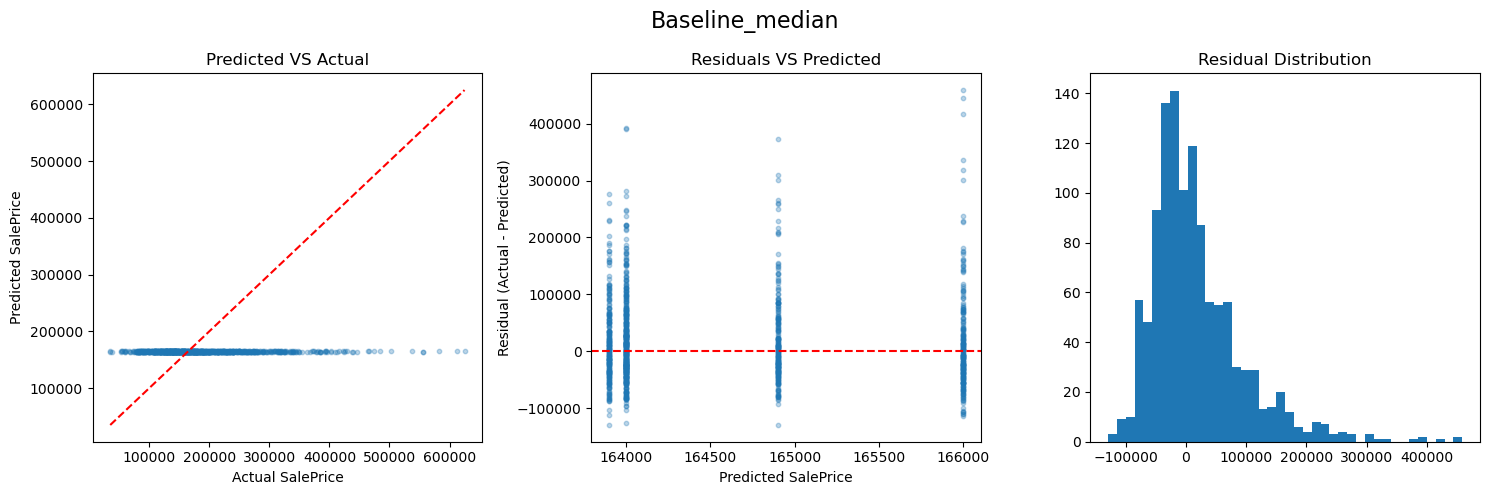

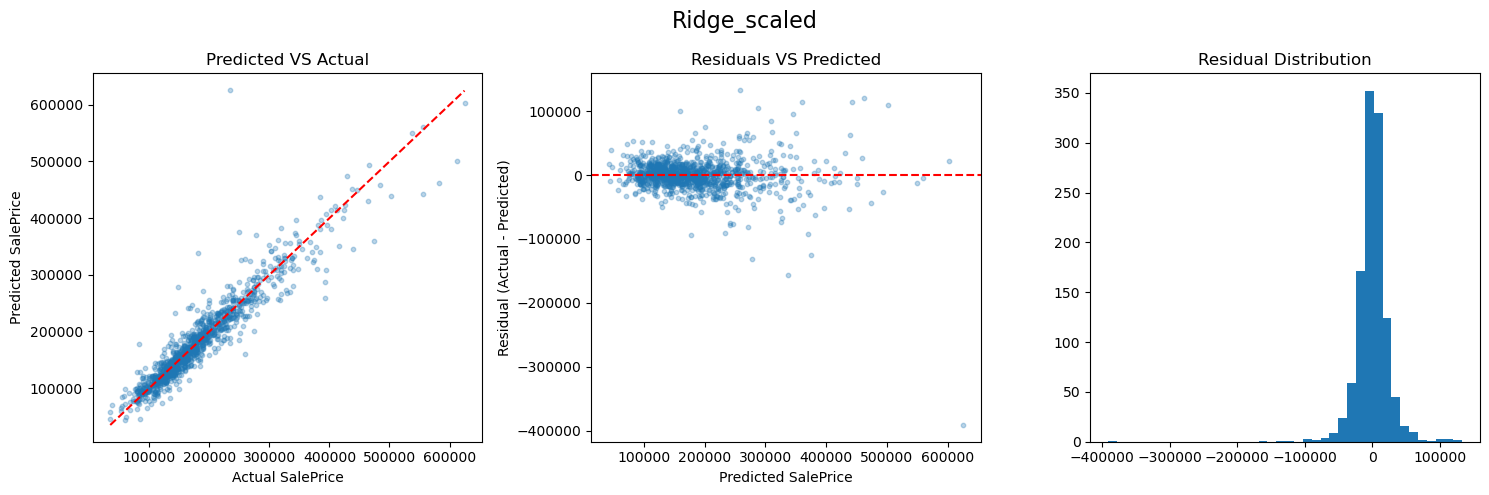

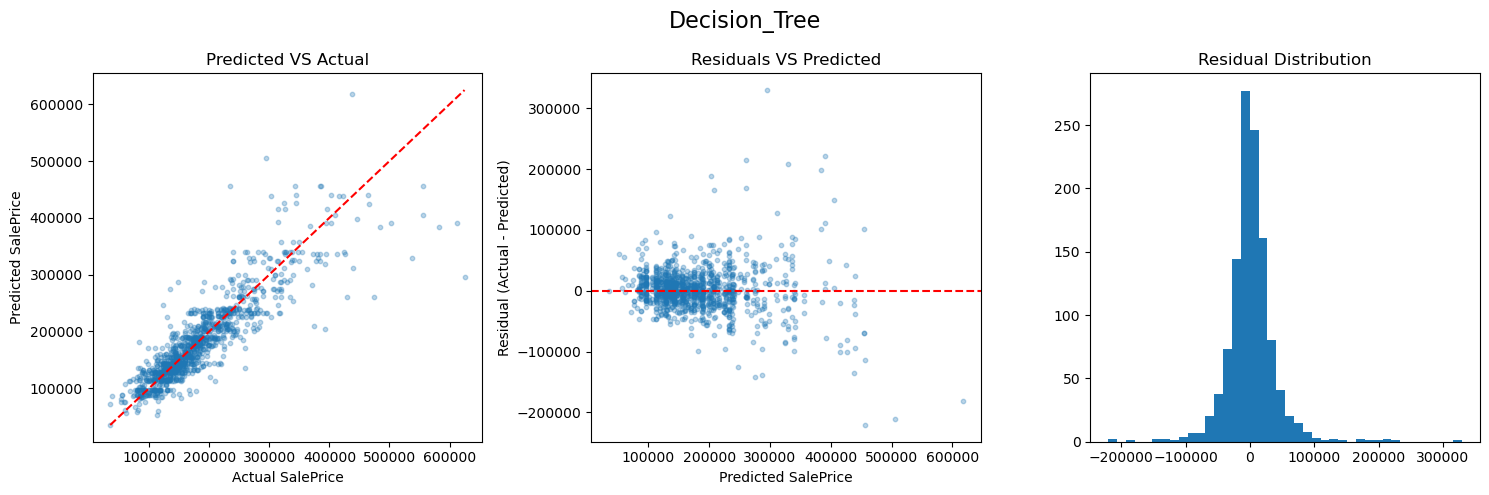

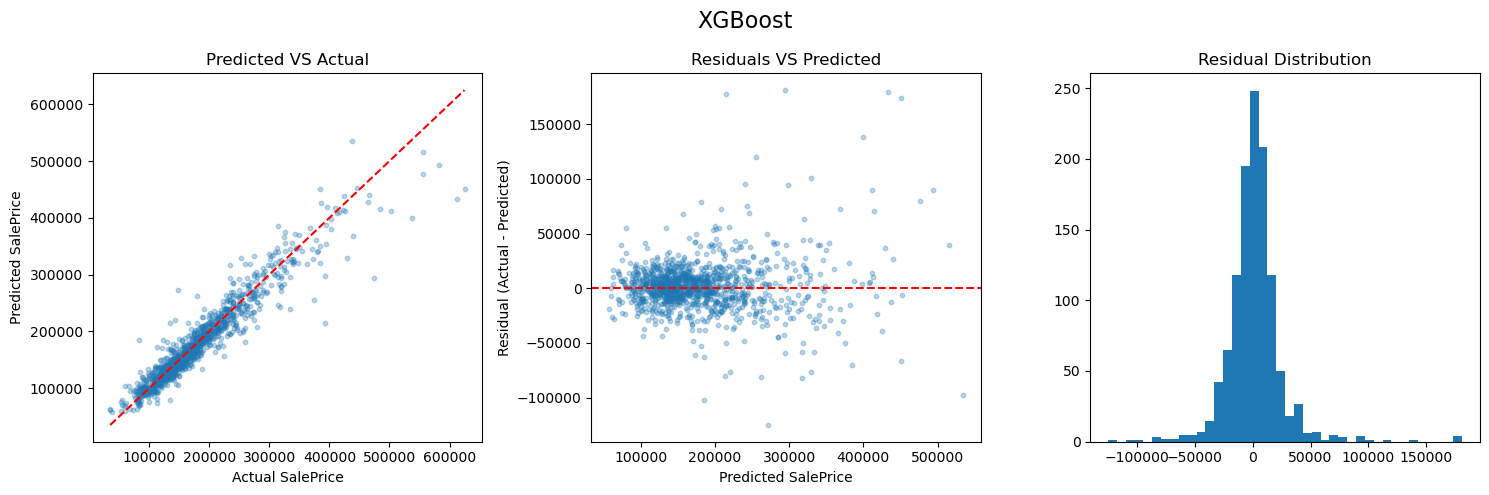

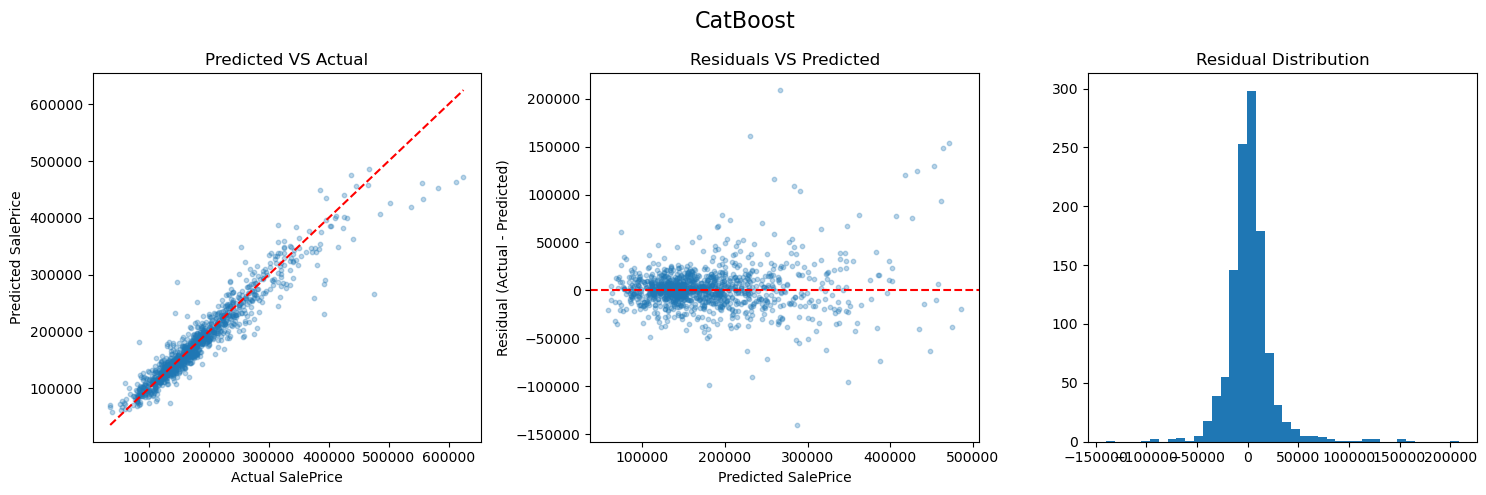

In [21]:
# Plotting residual plots for each model
actual_y_in_dollar = np.expm1(y_train)

for name, pred_in_log in oof_predictions.items():
    pred_in_dollar = np.expm1(pred_in_log)
    residuals = actual_y_in_dollar - pred_in_dollar

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))

    ax[0].scatter(actual_y_in_dollar, pred_in_dollar, alpha=0.3, s=10)
    x_limit = [actual_y_in_dollar.min(), actual_y_in_dollar.max()]
    ax[0].plot(x_limit, x_limit, "r--")
    ax[0].set_xlabel("Actual SalePrice")
    ax[0].set_ylabel("Predicted SalePrice")
    ax[0].set_title("Predicted VS Actual")

    ax[1].scatter(pred_in_dollar, residuals, alpha=0.3, s=10)
    ax[1].axhline(0, color="r", linestyle="--")
    ax[1].set_xlabel("Predicted SalePrice")
    ax[1].set_ylabel("Residual (Actual - Predicted)")
    ax[1].set_title("Residuals VS Predicted")

    ax[2].hist(residuals, bins=40)
    ax[2].set_title("Residual Distribution")

    fig.suptitle(name, fontsize=16)

    plt.tight_layout()
    plt.show()

Baseline: Predictions are almost constant (~$165k), leading to large residuals.

Ridge (scaled): Captures the overall price relationship, but residuals widen at higher prices, suggesting it did not capture non linear relationships well.

Decision Tree: Captures nonlinearity but had a more scattered redidual and piecewise-constant predictions.

XGBoost: Has a close fit with actual prices, with residuals are mostly centred around zero. Residuals widen at higher prices, suggesting that model has difficulty predicting expensive houses.

CatBoost: Similar to XGBoost, predictions are generally close to actual prices and residuals are around zero. It also has difficulty predicting expensive houses.

### 4. Model Improvement

I would be improving 3 models using hyperparameter tuning: Ridge using RidgeCV, and XGBoost and CatBoost with randomised search.
1) Ridge (using Ridge CV)
   - Hyperparameters tested: 
      - alpha --> controls the strength of regularisation
2) XGBoost
   - Hyperparameters tested: 
      - n_estimators --> maximum number of boosting iterations
      - max_depth --> maximum depth of each tree
      - learning_rate --> step size of each boosting iteration
      - subsample --> proportion of training samples used per tree
      - colsample_bytree --> proportion of features used per tree
      - min_child_weight --> controls the minimum number of data needed a leaf needs for each split
      - gamma --> miniumum improvement required a leaf needs before it can split
      - reg_alpha --> L1 regularisation (discards some unimportant feature weights)
      - reg_lambda --> L2 regularisation (keep all weights but shrinks them)
   - Early stopping was used to reduce overfitting
3) CatBoost
   - Hyperparameters tested:
      - depth --> depth of each tree
      - learning_rate --> step size of each boosting iteration
      - l2_leaf_reg --> strength of regularisation
      - iterations --> maximum number of boosting iterations
      - bagging_temperature --> controls how randomly samples are weighted when building each tree
   - Early stopping was used to reduce overfitting

In [ ]:
# Tuning RidgeCV
alphas = np.logspace(-3, 3, 50) # 50 evenly spaced numbers from 0.001 to 1000

ridge_cv_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", RidgeCV(alphas=alphas, cv=cv, scoring="neg_root_mean_squared_error")),
])

ridge_cv_pipeline.fit(X_train, y_train)
best_alpha = ridge_cv_pipeline.named_steps["ridge"].alpha_
print("Best alpha:", best_alpha)

Best alpha: 323.745754281764


In [23]:
run_all_enabled = False
if run_all_enabled:
    raise ValueError("You are running all the cells...")

In [ ]:
# Tuning XGBoost and CatBoost using random search with early stopping
def random_search_early_stopping(model_class, param_distribution, X, y, cv, n_iter=50, early_stopping_rounds=50, random_state=42):
    rdm = random.Random(random_state)
    results = []

    for i in range(n_iter):
        #  randomly sample one hyperparameter configuration 
        params = {k: rdm.choice(v) for k, v in param_distribution.items()}

        fold_rmse = []
        best_iterations = []

        print(f"\n[{model_class.__name__}] Iteration {i + 1}/{n_iter}")
        for k, v in params.items():
            print(f"\t{k}: {v}")

        for train_idx, val_idx in cv.split(X):
            X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
            y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

            model = model_class(**params, random_state=random_state)

            if model_class.__name__ == "XGBRegressor":
                model.set_params(early_stopping_rounds=early_stopping_rounds, eval_metric="rmse")
                model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
                best_iterations.append(model.best_iteration + 1)

            elif model_class.__name__ == "CatBoostRegressor":
                model.set_params(verbose=0, eval_metric="RMSE")
                model.fit(X_tr, y_tr, eval_set=(X_val, y_val), early_stopping_rounds=early_stopping_rounds, verbose=False)
                best_iterations.append(model.get_best_iteration() + 1)

            else:
                raise ValueError(
                    f"Unsupported model class: {model_class.__name__}. "
                    "Expected XGBRegressor or CatBoostRegressor"
                )

            preds = model.predict(X_val)
            fold_rmse.append(root_mean_squared_error(y_val, preds))

        results.append({
            "model": model_class.__name__,
            **params,
            "rmse_mean": np.mean(fold_rmse),
            "rmse_std": np.std(fold_rmse),
            "avg_best_iteration": np.mean(best_iterations),
        })
        print(
            f"[{model_class.__name__}] Iteration {i + 1}/{n_iter} | "
            f"RMSE = {np.mean(fold_rmse):.5f} | "
            f"Avg trees = {np.mean(best_iterations):.0f}"
        )

    return pd.DataFrame(results).sort_values("rmse_mean")


# XGBoost hyperparameter search space
xgb_params = {
    "n_estimators": [3000], # uses early stopping to find the real number
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.3, 1],
    "reg_alpha": [0, 0.01, 0.1, 1],
    "reg_lambda": [1, 3, 10],
}
xgb_results = random_search_early_stopping(
    XGBRegressor, xgb_params, X_train, y_train, cv
)
xgb_results.to_csv("model_training/xgb_results.csv", index=False)

# CatBoost hyperparameter search space
cat_params = {
    "iterations": [3000], # uses early stopping to find the real number
    "depth": [4, 6, 8, 10],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "l2_leaf_reg": [1, 3, 5, 10],
    "bagging_temperature": [0, 0.5, 1, 2],
}
cat_results = random_search_early_stopping(
    CatBoostRegressor, cat_params, X_train, y_train, cv
)
cat_results.to_csv("model_training/cat_results.csv", index=False)


[XGBRegressor] Iteration 1/50
	n_estimators: 3000
	max_depth: 3
	learning_rate: 0.05
	subsample: 0.6
	colsample_bytree: 0.6
	min_child_weight: 1
	gamma: 0
	reg_alpha: 0
	reg_lambda: 10
[XGBRegressor] Iteration 1/50 | RMSE = 0.11581 | Avg trees = 432

[XGBRegressor] Iteration 2/50
	n_estimators: 3000
	max_depth: 3
	learning_rate: 0.01
	subsample: 0.6
	colsample_bytree: 0.6
	min_child_weight: 1
	gamma: 0
	reg_alpha: 0.01
	reg_lambda: 10
[XGBRegressor] Iteration 2/50 | RMSE = 0.11449 | Avg trees = 1549

[XGBRegressor] Iteration 3/50
	n_estimators: 3000
	max_depth: 4
	learning_rate: 0.1
	subsample: 1.0
	colsample_bytree: 0.8
	min_child_weight: 1
	gamma: 0.1
	reg_alpha: 1
	reg_lambda: 3
[XGBRegressor] Iteration 3/50 | RMSE = 0.13276 | Avg trees = 53

[XGBRegressor] Iteration 4/50
	n_estimators: 3000
	max_depth: 4
	learning_rate: 0.03
	subsample: 0.8
	colsample_bytree: 0.6
	min_child_weight: 1
	gamma: 1
	reg_alpha: 0
	reg_lambda: 3
[XGBRegressor] Iteration 4/50 | RMSE = 0.14457 | Avg trees 

### 5. Model Evaluation

In [25]:
# Fitting each model with best hyparameters and retrain with CV
best_xgb_result = xgb_results.iloc[0] # sorted by rmse_mean
best_cat_result = cat_results.iloc[0] # sorted by rmse_mean

# XGBoost best parameters
xgb_best_params = {
    k: v for k, v in best_xgb_result.items()
    if k not in ["model", "rmse_mean", "rmse_std", "avg_best_iteration"]
}
xgb_best_params = {
    k: v.item() if hasattr(v, "item") else v
    for k, v in xgb_best_params.items()
}
xgb_best_params["n_estimators"] = int(round(float(best_xgb_result["avg_best_iteration"])))

# CatBoost best parameters
cat_best_params = {
    k: v for k, v in best_cat_result.items()
    if k not in ["model", "rmse_mean", "rmse_std", "avg_best_iteration"]
}
cat_best_params = {
    k: v.item() if hasattr(v, "item") else v
    for k, v in cat_best_params.items()
}
cat_best_params["iterations"] = int(round(float(best_cat_result["avg_best_iteration"])))


print("Ridge best hyperparameters: \n\talpha:", best_alpha)
print("\nXGBoost best hyperparameters:")
for k, v in xgb_best_params.items():
    print(f"\t{k}: {v}")
print("\nCatBoost best hyperparameters:")
for k, v in cat_best_params.items():
    print(f"\t{k}: {v}")


tuning_comparision_models = {
    "Ridge_original": Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0, random_state=42)),
    ]),
    "Ridge_tuned": Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=best_alpha, random_state=42)),
    ]),
    "XGBoost_original": XGBRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=4, random_state=42
    ),
    "XGBoost_tuned": XGBRegressor(
        **xgb_best_params, random_state=42
    ),
    "CatBoost_original": CatBoostRegressor(
        iterations=500, learning_rate=0.05, depth=6, random_state=42, verbose=0
    ),
    "CatBoost_tuned": CatBoostRegressor(
        **cat_best_params, random_state=42, verbose=0
    ),
}

cv_comparison_results = []
for name, model in tuning_comparision_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_comparison_results.append({
        "model": name,
        "rmse_mean": -scores["test_rmse"].mean(),
        "rmse_std": scores["test_rmse"].std(),
        "mae_mean": -scores["test_mae"].mean(),
        "r2_mean": scores["test_r2"].mean(),
    })

cv_comparison_df = pd.DataFrame(cv_comparison_results).sort_values("rmse_mean")
cv_comparison_df

Ridge best hyperparameters: 
	alpha: 323.745754281764

XGBoost best hyperparameters:
	n_estimators: 1549
	max_depth: 3
	learning_rate: 0.01
	subsample: 0.6
	colsample_bytree: 0.6
	min_child_weight: 1
	gamma: 0.0
	reg_alpha: 0.01
	reg_lambda: 10

CatBoost best hyperparameters:
	iterations: 1423
	depth: 4
	learning_rate: 0.01
	l2_leaf_reg: 1
	bagging_temperature: 0.5


,model,rmse_mean,rmse_std,mae_mean,r2_mean
5,CatBoost_tuned,0.113859,0.011021,0.078786,0.915292
3,XGBoost_tuned,0.114995,0.012034,0.079007,0.913828
4,CatBoost_original,0.115829,0.010231,0.079155,0.912596
1,Ridge_tuned,0.117357,0.009990,0.083992,0.910328
2,XGBoost_original,0.120017,0.010748,0.084431,0.906717
0,Ridge_original,0.128771,0.014223,0.089316,0.892396


Hyperparameter tuning was successful, improving performance across all three models, with tuned versions achieving lower RMSE and MAE and higher R squared compared to their original counterparts.

 - Catboost: RMSE decreased from 0.1158 to 0.1139 (~1.64% improvement), while R squared increased from 0.9126 to 0.9153
 - XGBoost: RMSE decreased from 0.1200 to 0.1150 (~4.17% improvement), while R squared increased from 0.9067 to 0.9138
 - Ridge: RMSE decreased from 0.1288 to 0.1174 (~8.85% improvement), while R squared increased from 0.8924 to 0.9103

In [ ]:
best_model_name = cv_comparison_df.iloc[0]["model"]
best_model = tuning_comparision_models[best_model_name]

best_model.fit(X_train, y_train)

best_pred_in_log = best_model.predict(X_test)
best_pred_in_dollar = np.expm1(best_pred_in_log)
y_test_in_dollar = np.expm1(y_test)

print("Final model:", " ".join(best_model_name.title().split("_")))
print("Test RMSE (log)", root_mean_squared_error(y_test, best_pred_in_log))
print("Test RMSE (dollar)", root_mean_squared_error(y_test_in_dollar, best_pred_in_dollar))
print("Test MAE (dollar)", mean_absolute_error(y_test_in_dollar, best_pred_in_dollar))
print("Test R Squared", r2_score(y_test, best_pred_in_log))

Final model: Catboost Tuned
Test RMSE (log) 0.11937238515136205
Test RMSE (dollar) 19558.275502043016
Test MAE (dollar) 13578.082883119781
Test R Squared 0.9097764716010738


### 6. Conclusion

This project compared four modelling approaches for predicting Ames housing sale price, using 5 fold CV for model selection and RMSE/MAE/R squared as evaluation metrics. All models significantly outperformed a median predictor baseline (RMSE = 0.3952), confirming that meaningful signal was captured in the engineered features. Among untuned (original) models, CatBoost performed best (CV RMSE = 0.1158, R squared = 0.9126), followed by XGBoost (CV RMSE = 0.1200, R squared = 0.9067), Ridge regression (CV RMSE = 0.1288) and Decision Tree (CV RMSE = 0.1827).

Hyperparameter Tuning: <br>
Hyperparameter tuning via random search improved every model, with Ridge having ~8.85% improvement in RMSE. CatBoost (tuned) is the best model (RMSE in log = 0.1194, RMSE in dollar = $19558.28, MAE = $13578.08), suggesting that my model generalised well to unseen data.

Limitations: 
 - Residual analysis showed all models, especially CatBoost and XGBoost, struggled more on more expensive houses. This might be becuase expensive houses are rare in this dataset, even after removing 4 outlier rows of GrLivArea > 4000.
 - Random search was performed with a fixed budget of 50 combinations, rather than performing grid search which searches all possible configurations. Although this greatly reduces the number of model configurations tested, it also reduces the coverage of the hyperparameter space. Thus, the best sample selected from the 50 sampled combinations might not be the optimal hyperparameter configuration.

Future Improvements: <br>
Possible improvements could include a more exhaustive hyperparameter search (e.g. Bayesian hyperparameter tuning with Optuna) to direct the search towards regions of the hyperparameter space most likely to achieve optimal performance. To address weaker performance on expensive houses, a weighted loss during training could be explored. Additionally, ensembling XGBoost and CatBoost predictions could be tested, since both performed similarly well and their distinct architectural approaches may capture complementary patterns to reduce individual blind spots.